# Programming for AI, Assignment 3
NumPy, Pandas and Matplotlib on real measurement data

National University of Computer and Emerging Sciences | Fall 2026 | Total Marks: 100

## Instructions
- Work only in this notebook. Fill the cells marked `# YOUR CODE HERE` and the markdown cells marked **ANSWER**.
- Allowed libraries: numpy, pandas, matplotlib. Do not change the names of the data files.
- Use a fixed seed (`np.random.seed(42)`) wherever you need random numbers.
- Every interpretation must refer to actual numbers from your own output. Generic statements get zero.
- Your notebook must run top to bottom with Kernel > Restart and Run All. Notebooks that fail halfway lose 10 marks.
- Q1 and Q2 must be answered by reasoning first. You may run code afterwards only to check yourself, but your written answer must explain the reasoning.
- Submit through GitHub as described in the PDF.

| Question | Topic | Marks |
|---|---|---|
| 1 | Code tracing | 12 |
| 2 | Debugging | 10 |
| 3 | Sensor cube (NumPy) | 18 |
| 4 | Weather stations (Pandas) | 20 |
| 5 | Student performance (Pandas + NumPy) | 15 |
| 6 | Dashboard (Matplotlib) | 15 |
| 7 | Surfaces and animation | 10 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.animation import FuncAnimation, PillowWriter
np.random.seed(42)
print(np.__version__, pd.__version__)

2.5.4 3.1.1


## Question 1: Code tracing (12 marks, 3 each)
Predict the exact printed output of each block **without running it**. Write shapes as tuples and mention dtype where it matters. Then add one or two sentences saying which line is the trap.

### 1.a
```python
import numpy as np
a = np.arange(24).reshape(2, 3, 4)
b = a[:, ::-1, -2:]
b[0, 0, 0] = 99
print(b.shape)
print(a[0, 2, 2])
print(a[:, 1, :].sum(axis=0))
print(b.T.shape)
```
**ANSWER:**
```
(2, 3, 2)
99
[20 22 24 26]
(2, 3, 2)
```
`a` has shape (2, 3, 4). `a[:, ::-1, -2:]` keeps both blocks, reverses the 3 rows and keeps the last 2 columns, so `b.shape` is (2, 3, 2). Slicing gives a view, so `b[0, 0, 0]` is the same memory as `a[0, 2, 2]` (reversed row 0 is row 2, and the last two columns are 2 and 3). Writing 99 into `b` therefore changes `a`, and `a[0, 2, 2]` prints 99 instead of 10. Row 1 is untouched: [4 5 6 7] + [16 17 18 19] = [20 22 24 26]. `b.T` reverses the axes, and (2, 3, 2) reversed is again (2, 3, 2).

**Trap:** `b[0, 0, 0] = 99` because `b` is a view, so the original array `a` changes too.

### 1.b
```python
import numpy as np
x = np.array([10, 20, 30, 40, 50, 60])
idx = np.array([-1, 0, -2, 2])
y = x[idx]
y[0] = 0
print(x)
z = x[1:4]
z[:] = 7
print(x)
print(x[[-1, -1, 0]])
```
**ANSWER:**
```
[10 20 30 40 50 60]
[10  7  7  7 50 60]
[60 60 10]
```
`x[idx]` uses an integer array (fancy indexing), which always makes a copy: `y = [60 10 50 30]`. So `y[0] = 0` does not touch `x` and the first print is the original array. `x[1:4]` is a slice, which is a view, so `z[:] = 7` writes 7 into `x[1]`, `x[2]` and `x[3]`. `x[[-1, -1, 0]]` takes the last element twice and then the first one: [60 60 10].

**Trap:** `y[0] = 0` changes only a copy (fancy indexing), but `z[:] = 7` changes `x` because a slice is a view.

### 1.c
```python
import numpy as np
s = np.array([3.9, -3.9, 2.5, 3.5, -0.5])
print(s.astype(int))
print(np.round(s))
print(np.array(['1', '2.5']).astype(float).dtype)
print((s > 0).sum(), (s > 0).any(), (np.abs(s) > 3).all())
```
**ANSWER:**
```
[ 3 -3  2  3  0]
[ 4. -4.  2.  4. -0.]
float64
3 True False
```
`astype(int)` cuts off the decimal part (truncates toward zero): 3.9 gives 3, -3.9 gives -3, 2.5 gives 2, 3.5 gives 3, -0.5 gives 0. `np.round` rounds halves to the nearest even number: 2.5 gives 2.0, 3.5 gives 4.0, and -0.5 gives -0.0 (a negative zero), while 3.9 gives 4.0 and -3.9 gives -4.0. The text array `['1', '2.5']` converts to float64. `s > 0` is True for 3.9, 2.5, 3.5, so the sum is 3 and `any` is True. `np.abs(s) > 3` is [T, T, F, T, F], so `all` is False.

**Trap:** `np.round(2.5)` is 2.0 and `np.round(-0.5)` is -0.0 (round half to even), and `astype(int)` truncates instead of rounding.

### 1.d
```python
import numpy as np
A = np.arange(6).reshape(2, 3)
B = np.array([[10], [20]])
C = np.array([1, 2, 3])
print(A + B + C)
print(A @ C)
print(A * C)
print(np.cumprod(C + 1))
print(A.sum(axis=0) - A.sum(axis=1)[0])
```
**ANSWER:**
```
[[11 13 15]
 [24 26 28]]
[ 8 26]
[[ 0  2  6]
 [ 3  8 15]]
[ 2  6 24]
[0 2 4]
```
`A` is (2, 3) and `B` is (2, 1). Adding `B` stretches its column across 3 columns, giving [[10 11 12], [23 24 25]]. Adding `C` (shape (3,)) adds [1 2 3] to every row, giving [[11 13 15], [24 26 28]]. `A @ C` is a matrix-vector product: 0*1+1*2+2*3 = 8 and 3*1+4*2+5*3 = 26. `A * C` is element-wise with `C` repeated on each row. `C + 1` is [2 3 4] and its cumulative product is [2 6 24]. `A.sum(axis=0)` is [3 5 7] and `A.sum(axis=1)[0]` is 0+1+2 = 3, so the result is [3 5 7] - 3 = [0 2 4].

**Trap:** the last line, because `A.sum(axis=1)[0]` is only the first row sum (3, a single number), not the row sums [3 12]. Also `A @ C` (matrix product) is not the same as `A * C` (element-wise).

## Question 2: Debugging (10 marks, 2 each)
For each snippet: (i) name the exact exception or the silent logical bug, (ii) explain why in one or two sentences, (iii) write corrected code in the code cell below it, (iv) state the corrected output or shape.

### 2.a
```python
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2, 3], [4, 5, 6]])
print(np.dot(A, B))
```
Intended: the 2x2 matrix of dot products between rows of A and rows of B.

**ANSWER:**
- (i) `ValueError`: shapes (2,3) and (2,3) not aligned: 3 (dim 1) != 2 (dim 0).
- (ii) `np.dot` of two 2-D arrays is a matrix product, so the inner sizes must match (3 and 2 do not). Dot products between rows of A and rows of B need B transposed.
- (iv) Corrected code `A @ B.T` gives shape (2, 2): [[14 32], [32 77]] (for example 1*1 + 2*2 + 3*3 = 14).

In [2]:
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2, 3], [4, 5, 6]])
print(A @ B.T)

[[14 32]
 [32 77]]


### 2.b
```python
scores = np.arange(12, dtype=float).reshape(3, 4)
centered = scores - scores.mean(axis=1)
print(centered)
```
Intended: subtract each row's own mean from that row.

**ANSWER:**
- (i) `ValueError`: operands could not be broadcast together with shapes (3,4) (3,).
- (ii) `scores.mean(axis=1)` has shape (3,). Broadcasting compares shapes from the right, so 4 is compared with 3 and fails. With `keepdims=True` the mean has shape (3, 1) and stretches across the 4 columns.
- (iv) Corrected output has shape (3, 4) and every row is [-1.5 -0.5 0.5 1.5].

In [3]:
scores = np.arange(12, dtype=float).reshape(3, 4)
centered = scores - scores.mean(axis=1, keepdims=True)
print(centered)

[[-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]]


### 2.c
```python
fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax[1].plot([1, 2, 3], [3, 1, 2])
ax[0, 0].set_title('Left')
ax[2, 0].hist(np.random.randn(100))
```
Intended: line plot in the bottom-left panel and histogram in the bottom-right panel.

**ANSWER:**
- (i) `AttributeError`: 'numpy.ndarray' object has no attribute 'plot'. With a 2x2 grid `ax` is a 2-D array, so `ax[1]` is the whole second row (two Axes). The next line `ax[2, 0]` would also fail with `IndexError` (index 2 is out of bounds for axis 0 with size 2).
- (ii) Every panel must be addressed with two indices [row, column]: bottom-left is `ax[1, 0]` and bottom-right is `ax[1, 1]`.
- (iv) Corrected output is a 2x2 figure: title "Left" on the top-left panel, the line plot bottom-left, the histogram of 100 values bottom-right, and the top-right panel empty.

(array([ 1.,  4.,  6.,  8., 19., 17., 21., 11.,  6.,  7.]),
 array([-2.6197451 , -2.17254278, -1.72534045, -1.27813812, -0.83093579,
        -0.38373346,  0.06346887,  0.5106712 ,  0.95787353,  1.40507586,
         1.85227818]),
 <BarContainer object of 10 artists>)

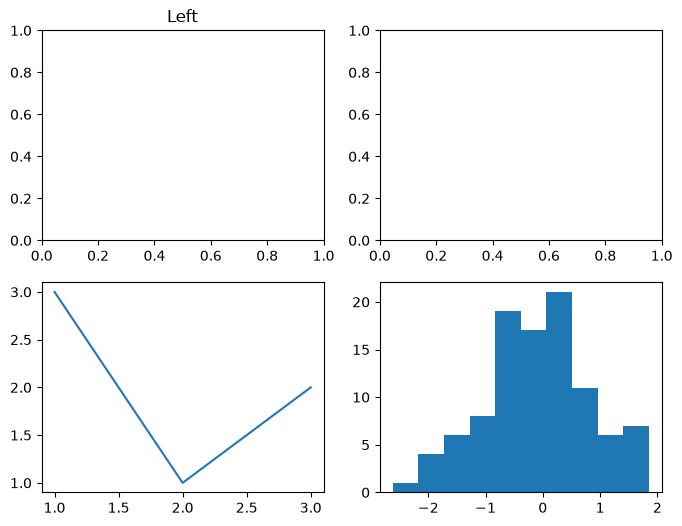

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax[1, 0].plot([1, 2, 3], [3, 1, 2])
ax[0, 0].set_title('Left')
ax[1, 1].hist(np.random.randn(100))

### 2.d
```python
marks = np.array([[35., 80., 55.], [20., 90., 45.]])
first = marks[:, 0]
first[first < 40] = 40          # curve for display only
print(marks.mean(axis=0))
```
Intended: the original marks must remain unchanged, the curved copy is used only for display.

**ANSWER:**
- (i) Silent logical bug, no exception is raised.
- (ii) `marks[:, 0]` is a view, so `first[first < 40] = 40` changes the original `marks` too. The buggy code prints [40. 85. 50.], which is wrong because the original 35 and 20 were overwritten by 40.
- (iv) With `.copy()` the original means are [27.5 85. 50.] and the curved copy used for display is [40. 40.].

In [5]:
marks = np.array([[35., 80., 55.], [20., 90., 45.]])
first = marks[:, 0].copy()      # copy, so marks itself is not changed
first[first < 40] = 40          # curve for display only
print(marks.mean(axis=0))       # original marks
print(first)                    # curved copy for display

[27.5 85.  50. ]
[40. 40.]


### 2.e
```python
x = np.linspace(0, 1, 50)
y = np.linspace(0, 1, 30)
X, Y = np.meshgrid(x, y)
Z = np.sin(3 * x) * np.cos(2 * Y)
fig, ax = plt.subplots()
im = ax.pcolormesh(X, Y, Z)
plt.colorbar()
```
Intended: heatmap of sin(3x)cos(2y) with a working colorbar and no shape error.

**ANSWER:**
- (i) `RuntimeError`: No mappable was found to use for colorbar creation.
- (ii) `plt.colorbar()` without arguments looks for the current image of pyplot, but the plot was made with `ax.pcolormesh`, so none is found. The mappable must be passed: `fig.colorbar(im, ax=ax)`. Also, `np.sin(3 * x)` uses the 1-D `x` instead of the 2-D `X`. It still works here because (50,) broadcasts with (30, 50), so there is no shape error, but I used `X` to keep all arrays the same shape.
- (iv) `Z` has shape (30, 50) and the figure shows the heatmap with a working colorbar.

(30, 50)


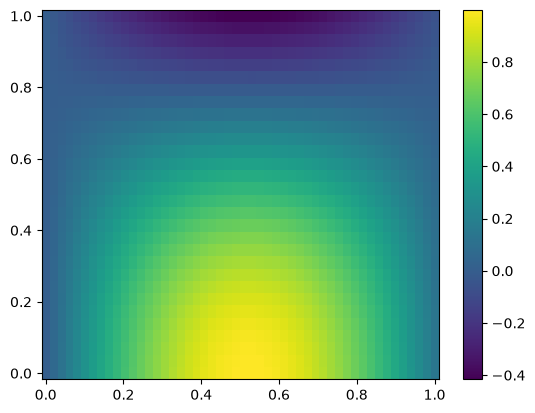

In [6]:
x = np.linspace(0, 1, 50)
y = np.linspace(0, 1, 30)
X, Y = np.meshgrid(x, y)
Z = np.sin(3 * X) * np.cos(2 * Y)
fig, ax = plt.subplots()
im = ax.pcolormesh(X, Y, Z)
fig.colorbar(im, ax=ax)
print(Z.shape)

## Question 3: Sensor cube (18 marks)
`data/sensor_cube.npy` holds temperature readings from 6 sensors over 10 days, 24 hours per day. Axes are (day, hour, sensor). `data/sensor_meta.npz` holds `offsets` (calibration per sensor), `sensor_ids` and `days`. The logger writes -999 when a reading fails. Some other readings are physically impossible for this site (below 0 or above 60 degrees C).

**3a (3 marks)** Load both files. Print the shape, dtype and size of the cube, list the arrays stored in the npz archive and print `sensor_ids`. Report how many readings equal -999 and how many other readings are impossible. Why is -999 more dangerous than NaN if you take a mean directly?

In [7]:
cube = np.load('data/sensor_cube.npy')
meta = np.load('data/sensor_meta.npz')

print('shape:', cube.shape, '| dtype:', cube.dtype, '| size:', cube.size)
print('arrays in npz:', meta.files)
print('sensor_ids:', meta['sensor_ids'])

failed = (cube == -999)
impossible = ((cube < 0) | (cube > 60)) & ~failed
print('readings equal to -999:', failed.sum())
print('other impossible readings:', impossible.sum())

# why -999 is dangerous
mean_with_999 = cube.mean()
mean_with_nan = np.where(failed, np.nan, cube).mean()
print('mean with -999 left in:', round(mean_with_999, 2), '| mean with NaN left in:', mean_with_nan)
print('-999 is a normal-looking number, so the mean is silently pulled down and no error shows up.')
print('NaN makes the mean NaN, so the problem is visible straight away.')

shape: (10, 24, 6) | dtype: float64 | size: 1440
arrays in npz: ['offsets', 'sensor_ids', 'days']
sensor_ids: ['T1' 'T2' 'T3' 'T4' 'T5' 'T6']
readings equal to -999: 27
other impossible readings: 2
mean with -999 left in: 8.91 | mean with NaN left in: nan
-999 is a normal-looking number, so the mean is silently pulled down and no error shows up.
NaN makes the mean NaN, so the problem is visible straight away.


**3b (4 marks)** Make a float copy of the cube (not a view) where every failed or impossible reading is NaN. Prove with `np.shares_memory` that your copy is independent. Then apply calibration by adding `offsets` using broadcasting only, no loops. State the shape of the broadcast operand and why it aligns with the last axis. Write the check that the original file array is untouched.

In [8]:
offsets = meta['offsets']

clean = cube.astype(float)          # astype makes a new array (a copy)
bad = (cube == -999) | (cube < 0) | (cube > 60)
clean[bad] = np.nan
print('NaN count in clean copy:', np.isnan(clean).sum())
print('shares memory with original cube?', np.shares_memory(cube, clean))

calibrated = clean + offsets        # offsets has shape (6,), broadcast to (1, 1, 6)
print('offsets shape:', offsets.shape, '| cube shape:', cube.shape, '| calibrated shape:', calibrated.shape)
print('Broadcasting compares shapes from the right, so (6,) lines up with the last axis (6 sensors).')

# check that the original array is untouched
print('original still has', (cube == -999).sum(), 'values equal to -999')
print('original equals the file on disk:', np.array_equal(cube, np.load('data/sensor_cube.npy')))

NaN count in clean copy: 29
shares memory with original cube? False
offsets shape: (6,) | cube shape: (10, 24, 6) | calibrated shape: (10, 24, 6)
Broadcasting compares shapes from the right, so (6,) lines up with the last axis (6 sensors).
original still has 27 values equal to -999
original equals the file on disk: True


**3c (4 marks)** Without loops compute: (i) the mean temperature of each sensor over all days and hours, (ii) the mean daily profile of each hour averaged over days and sensors (shape 24), (iii) the hottest (day, sensor) pair using daily means. NaN must not poison the result. State the axis you used for each and why.

In [9]:
# (i) mean of each sensor: collapse day (axis 0) and hour (axis 1), keep sensor (axis 2)
sensor_mean = np.nanmean(calibrated, axis=(0, 1))
print('mean per sensor:', sensor_mean.round(2))

# (ii) mean daily profile: collapse day (axis 0) and sensor (axis 2), keep hour (axis 1)
hour_profile = np.nanmean(calibrated, axis=(0, 2))
print('profile shape:', hour_profile.shape)
print(hour_profile.round(2))

# (iii) hottest (day, sensor): daily mean collapses the hour axis (axis 1) -> shape (10, 6)
daily_mean = np.nanmean(calibrated, axis=1)
d, s = np.unravel_index(np.nanargmax(daily_mean), daily_mean.shape)
print('hottest pair: day', meta['days'][d], 'sensor', meta['sensor_ids'][s], 'daily mean', daily_mean[d, s].round(2))
# nanmean and nanargmax skip the NaN values, so they do not poison the result

mean per sensor: [27.99 29.06 25.91 28.29 30.48 27.22]
profile shape: (24,)
[23.29 22.03 21.31 21.16 21.43 21.88 23.22 24.36 26.2  28.22 30.12 31.58
 33.17 34.13 34.88 35.16 35.05 34.12 33.25 31.67 30.07 28.25 26.34 24.59]
hottest pair: day 10 sensor T5 daily mean 32.13


**3d (4 marks)** For sensor T3 (index 2) compute the 3-hour moving average of the hourly series for day 4 (index 3) using `np.cumsum` and slicing only, not `np.convolve`. Fill NaN in that series with the mean of the series first. Report the length of the result and explain why it is not 24.

In [10]:
series = calibrated[3, :, 2]        # day 4 (index 3), sensor T3 (index 2), 24 hourly values
print('NaN in this series:', np.isnan(series).sum())
series = np.where(np.isnan(series), np.nanmean(series), series)

c = np.insert(np.cumsum(series), 0, 0)   # c[k] = sum of the first k values
ma3 = (c[3:] - c[:-3]) / 3               # sum of each 3-hour window divided by 3
print('length of moving average:', len(ma3))
print(ma3.round(2))
print('Length is 24 - 3 + 1 =', len(ma3), 'because a window needs 3 hours, so the first 2 hours have no full window.')

NaN in this series: 1
length of moving average: 22
[19.2  18.9  18.56 18.79 19.53 20.54 21.97 23.44 25.19 27.16 28.29 29.94
 28.78 29.89 30.24 32.32 31.93 30.55 28.75 27.07 25.21 23.55]
Length is 24 - 3 + 1 = 22 because a window needs 3 hours, so the first 2 hours have no full window.


**3e (3 marks)** Count the hours per day in which at least one sensor is above 35 degrees C (use `any`), and the number of days in which all sensors stay below 35 for the whole day (use `all`). Using `np.unique` with counts on the hour of each day's peak (use the sensor-averaged series), state which hour is the most common peak. Interpret in two sentences: is the sensor network behaving like a daytime heating cycle?

In [11]:
hot = calibrated > 35                         # NaN > 35 is False, so NaN never counts as hot
hot_hours_per_day = hot.any(axis=2).sum(axis=1)
print('hours per day with at least one sensor above 35 C:', hot_hours_per_day)

below = (calibrated < 35) | np.isnan(calibrated)   # NaN readings are ignored
cool_days = below.all(axis=(1, 2))
print('days where all sensors stay below 35 C the whole day:', cool_days.sum())

avg_series = np.nanmean(calibrated, axis=2)   # (10 days, 24 hours), average of the sensors
peak_hour = np.nanargmax(avg_series, axis=1)  # hour of each day's peak
hours, counts = np.unique(peak_hour, return_counts=True)
print('peak hours:', hours, '| counts:', counts)
print('most common peak hour:', hours[counts.argmax()])

hours per day with at least one sensor above 35 C: [1 3 5 7 5 7 8 7 9 9]
days where all sensors stay below 35 C the whole day: 0
peak hours: [14 15 16] | counts: [1 5 4]
most common peak hour: 15


**ANSWER 3e interpretation:**

Yes, the network follows a daytime heating cycle: the sensor-averaged series peaks at hour 14 on 1 day, hour 15 on 5 days and hour 16 on 4 days (most common peak: hour 15), and the mean profile falls to its lowest value of 21.16 C at hour 3 and rises to 35.16 C at hour 15. No day stays below 35 C at every sensor (0 cool days), and the number of hours per day with at least one sensor above 35 C generally grows from 1 on day 1 to 9 on days 9 and 10, so the site also warms up over the 10 days.

## Question 4: Weather stations with Pandas (20 marks)
`data/weather_stations.csv` contains daily records for five cities. The file is messy: mixed date formats (`YYYY-MM-DD` and `DD/MM/YYYY`), temperatures stored as text such as `34.2C`, -999 as failed rain gauge value, missing humidity, pressure readings of 0 and duplicate rows.

**4a (6 marks)** Load and clean. Print `info()` before and after. Remove exact duplicates, parse both date formats into one datetime column (a plain `pd.to_datetime` call without care will silently misread days and months, check that), convert temperature to float, turn -999 into NaN, turn pressure 0 into NaN, fill missing humidity with the median humidity of the same city. Report the number of rows removed and the number of values you changed in each column. Name the cleaned frame `weather`.

In [12]:
weather = pd.read_csv('data/weather_stations.csv')
print('--- info BEFORE cleaning ---')
weather.info()
rows_before = len(weather)

# 1. remove exact duplicate rows
weather = weather.drop_duplicates()
rows_removed = rows_before - len(weather)

# 2. dates: two formats, so each format is parsed with its own format string
is_slash = weather['date'].str.contains('/')
iso = pd.to_datetime(weather.loc[~is_slash, 'date'], format='%Y-%m-%d')
dmy = pd.to_datetime(weather.loc[is_slash, 'date'], format='%d/%m/%Y')
# check: what a month-first reading of the DD/MM/YYYY rows would give
wrong = pd.to_datetime(weather.loc[is_slash, 'date'], format='%m/%d/%Y', errors='coerce')
misread = (wrong.isna() | (wrong != dmy)).sum()
print('DD/MM/YYYY rows:', is_slash.sum(), '| misread by a month-first parse:', misread,
      '(of which', wrong.isna().sum(), 'would not even parse)')
weather['date'] = pd.concat([iso, dmy]).sort_index()

# 3. temperature text like 34.2C -> float
n_temp_text = weather['temp_c'].str.endswith('C').sum()
weather['temp_c'] = weather['temp_c'].str.replace('C', '', regex=False).astype(float)

# 4. -999 rain -> NaN, 5. pressure 0 -> NaN
n_rain = (weather['rain_mm'] == -999).sum()
weather['rain_mm'] = weather['rain_mm'].replace(-999, np.nan)
n_pressure = (weather['pressure_hpa'] == 0).sum()
weather['pressure_hpa'] = weather['pressure_hpa'].replace(0, np.nan)

# 6. missing humidity -> median humidity of the same city
n_hum = weather['humidity_pct'].isna().sum()
city_median = weather.groupby('city')['humidity_pct'].transform('median')
weather['humidity_pct'] = weather['humidity_pct'].fillna(city_median)

weather = weather.sort_values(['city', 'date']).reset_index(drop=True)

print('\nrows removed (duplicates):', rows_removed)
changed = pd.Series({'date (DD/MM rows re-read correctly)': is_slash.sum(),
                     'temp_c (text C removed)': n_temp_text,
                     'rain_mm (-999 -> NaN)': n_rain,
                     'pressure_hpa (0 -> NaN)': n_pressure,
                     'humidity_pct (filled with city median)': n_hum})
print('values changed per column:')
print(changed)
print('date range:', weather['date'].min().date(), 'to', weather['date'].max().date(), '| NaT:', weather['date'].isna().sum())
print('\n--- info AFTER cleaning ---')
weather.info()

--- info BEFORE cleaning ---
<class 'pandas.DataFrame'>
RangeIndex: 608 entries, 0 to 607
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   station_id    608 non-null    str    
 1   city          608 non-null    str    
 2   date          608 non-null    str    
 3   temp_c        608 non-null    str    
 4   humidity_pct  583 non-null    float64
 5   pressure_hpa  608 non-null    float64
 6   rain_mm       608 non-null    float64
dtypes: float64(3), str(4)
memory usage: 33.4 KB
DD/MM/YYYY rows: 60 | misread by a month-first parse: 57 (of which 34 would not even parse)

rows removed (duplicates): 8
values changed per column:
date (DD/MM rows re-read correctly)       60
temp_c (text C removed)                   80
rain_mm (-999 -> NaN)                     18
pressure_hpa (0 -> NaN)                    4
humidity_pct (filled with city median)    25
dtype: int64
date range: 2026-03-01 to 2026-06-28 | NaT: 0

--- info

**4b (5 marks)** Create a month column. Build a pivot table of mean temperature by city (rows) and month (columns), rounded to 1 decimal. Find the city with the largest rise from the first month to the last month. Add a column giving each row's temperature anomaly relative to its own city's mean, using `groupby` with `transform`.

In [13]:
weather['month'] = weather['date'].dt.month
pivot = pd.pivot_table(weather, values='temp_c', index='city', columns='month', aggfunc='mean').round(1)
print(pivot)

# rise from the first month (3) to the last month (6)
rise = pivot[6] - pivot[3]
print('\nrise from month 3 to month 6:')
print(rise.round(1))
print('largest rise:', rise.idxmax(), '=', round(rise.max(), 1), 'C')

# anomaly = temperature minus the mean temperature of the same city
weather['temp_anomaly'] = (weather['temp_c'] - weather.groupby('city')['temp_c'].transform('mean')).round(2)
print(weather[['city', 'date', 'temp_c', 'temp_anomaly']].head())

month         3     4     5     6
city                             
Islamabad  30.5  29.2  34.9  35.0
Karachi    32.6  32.0  38.3  38.5
Lahore     33.8  33.2  39.0  39.2
Peshawar   33.1  32.8  37.9  38.3
Quetta     23.4  23.3  29.9  29.6

rise from month 3 to month 6:
city
Islamabad    4.5
Karachi      5.9
Lahore       5.4
Peshawar     5.2
Quetta       6.2
dtype: float64
largest rise: Quetta = 6.2 C
        city       date  temp_c  temp_anomaly
0  Islamabad 2026-03-01    28.1         -4.27
1  Islamabad 2026-03-02    25.7         -6.67
2  Islamabad 2026-03-03    27.3         -5.07
3  Islamabad 2026-03-04    29.9         -2.47
4  Islamabad 2026-03-05    29.6         -2.77


**4c (5 marks)** A heat spell is 3 or more consecutive days with temp above 38 in one city. Find every spell (city, start date, length). You may use NumPy on each city's sorted series, for example `diff` on a boolean array, but explain your logic in comments. If your data contains a missing calendar day for a city, say what you did about it.

In [14]:
spells = []
for city, g in weather.groupby('city'):
    s = g.set_index('date')['temp_c'].sort_index()

    # make sure every calendar day is present; a missing day becomes NaN and so is not "hot"
    all_days = pd.date_range(s.index.min(), s.index.max())
    print(city, '- missing calendar days:', len(all_days) - len(s))
    s = s.reindex(all_days)

    hot = (s.values > 38).astype(int)           # 1 on a hot day, 0 otherwise
    padded = np.concatenate([[0], hot, [0]])    # zeros at both ends so every run has a start and an end
    change = np.diff(padded)                    # +1 where a run starts, -1 right after it ends
    starts = np.where(change == 1)[0]
    ends = np.where(change == -1)[0]
    lengths = ends - starts                     # run length in days

    for st, ln in zip(starts, lengths):
        if ln >= 3:                             # a heat spell needs 3 or more days
            spells.append((city, all_days[st].date(), int(ln)))

spells_df = pd.DataFrame(spells, columns=['city', 'start_date', 'length_days'])
print(spells_df)
print('No calendar day is missing in my cleaned data, so nothing had to be filled. If one were missing it would break a spell.')

Islamabad - missing calendar days: 0
Karachi - missing calendar days: 0
Lahore - missing calendar days: 0
Peshawar - missing calendar days: 0
Quetta - missing calendar days: 0
         city  start_date  length_days
0   Islamabad  2026-06-25            3
1     Karachi  2026-05-12            5
2     Karachi  2026-05-20            3
3     Karachi  2026-06-18           11
4      Lahore  2026-05-05            4
5      Lahore  2026-05-10            5
6      Lahore  2026-05-16            7
7      Lahore  2026-06-16            7
8      Lahore  2026-06-24            5
9    Peshawar  2026-05-15            6
10   Peshawar  2026-06-17            4
11   Peshawar  2026-06-22            7
No calendar day is missing in my cleaned data, so nothing had to be filled. If one were missing it would break a spell.


**4d (4 marks)** Compute the correlation matrix of temperature, humidity, pressure and rain. Then compute it separately for Karachi only. Interpret: which relationships are weak overall but strong inside one city, and why could pooling cities mislead you (name the effect)? Rain is mostly zero, so also state what that does to a correlation coefficient.

In [15]:
cols = ['temp_c', 'humidity_pct', 'pressure_hpa', 'rain_mm']
print('All cities together:')
print(weather[cols].corr().round(2))

karachi = weather[weather['city'] == 'Karachi']
print('\nKarachi only:')
print(karachi[cols].corr().round(2))

# correlation of temperature and humidity inside each city
print('\ntemp vs humidity, per city:')
for city, g in weather.groupby('city'):
    print(city, round(g['temp_c'].corr(g['humidity_pct']), 2))
print('\nmean temp and humidity per city:')
print(weather.groupby('city')[['temp_c', 'humidity_pct']].mean().round(1))

# rain is mostly zero
print('\nshare of rain values equal to 0:', round((weather['rain_mm'] == 0).mean() * 100, 1), '%')
print('number of days with rain > 0:', (weather['rain_mm'] > 0).sum(), 'out of', weather['rain_mm'].notna().sum())

All cities together:
              temp_c  humidity_pct  pressure_hpa  rain_mm
temp_c          1.00         -0.39         -0.26     0.03
humidity_pct   -0.39          1.00          0.25     0.01
pressure_hpa   -0.26          0.25          1.00    -0.06
rain_mm         0.03          0.01         -0.06     1.00

Karachi only:
              temp_c  humidity_pct  pressure_hpa  rain_mm
temp_c          1.00         -0.58         -0.21    -0.05
humidity_pct   -0.58          1.00          0.19    -0.01
pressure_hpa   -0.21          0.19          1.00     0.01
rain_mm        -0.05         -0.01          0.01     1.00

temp vs humidity, per city:
Islamabad -0.47
Karachi -0.58
Lahore -0.54
Peshawar -0.52
Quetta -0.64

mean temp and humidity per city:
           temp_c  humidity_pct
city                           
Islamabad    32.4          51.4
Karachi      35.3          50.4
Lahore       36.2          51.0
Peshawar     35.5          49.4
Quetta       26.5          50.0

share of rain values equa

**ANSWER 4d interpretation:**

Temperature and humidity are the pair that is weak overall but stronger inside one city: the pooled correlation is -0.39, but inside Karachi it is -0.58 (the per-city values range from -0.47 for Islamabad to -0.64 for Quetta). Pooling cities misleads here because the cities differ a lot in mean temperature (Quetta 26.5 C, Lahore 36.2 C) but hardly at all in mean humidity (49.4 to 51.4 percent), so the between-city temperature differences carry no matching humidity change and dilute the relationship that exists within each city. This is a Simpson's-paradox-type effect, where a hidden grouping variable (city) changes the pooled correlation. The other pairs hardly change between the two tables (temperature and pressure -0.26 overall and -0.21 in Karachi), so they are not stronger inside Karachi. Rain correlations are all close to zero (between -0.06 and 0.03 overall, and -0.05 to 0.01 in Karachi), but this says very little because 83.5 percent of the rain values are 0 (only 81 of 582 readings show rain), so a handful of rainy days decide the coefficient and a near-zero r does not prove that rain is unrelated to the other variables.

## Question 5: Student performance (15 marks)
`data/student_performance.csv` has 240 students (some rows duplicated). Maximum marks are in the column names: quiz 20, assignment 20, midterm 25, final 35. Total = 100. Some midterms are the text `Absent`, some finals look like a typing slip (entered ten times too large), and some study hours are missing.

**5a (5 marks)** Clean the data. Absent counts as 0 for the total but must be kept in a separate boolean column. Fix finals that exceed 35 by the most defensible rule and say what rule you chose. Fill missing study hours with the section median. Create `total` and a `grade` column: A at 85 or more, B at 70 to 84.99, C at 55 to 69.99, D at 40 to 54.99, F below 40, using `np.where` (nested) or boolean masks, not a loop.

In [16]:
students = pd.read_csv('data/student_performance.csv')
rows_before = len(students)
students = students.drop_duplicates().reset_index(drop=True)
print('duplicate rows removed:', rows_before - len(students), '| students left:', len(students))

# Absent: keep a True/False column, then count the midterm as 0
students['absent_midterm'] = students['midterm_25'] == 'Absent'
students['midterm_25'] = pd.to_numeric(students['midterm_25'], errors='coerce').fillna(0)
print('absent in midterm:', students['absent_midterm'].sum())

# Finals above 35 are typing slips (ten times too large), so I divide them by 10
too_big = students['final_35'] > 35
print('finals fixed:', too_big.sum(), '| old values:', students.loc[too_big, 'final_35'].tolist())
students.loc[too_big, 'final_35'] = students.loc[too_big, 'final_35'] / 10
print('new values:', students.loc[too_big, 'final_35'].tolist())
print('Rule: divide by 10. The problem says the slip is exactly 10 times too large, so this gives back the real mark (307 -> 30.7).')
print('Capping at 35 would wrongly give full marks, and dropping the students would lose their other marks.')

# Missing study hours -> median of the same section
print('missing study hours:', students['study_hours_week'].isna().sum())
section_median = students.groupby('section')['study_hours_week'].transform('median')
students['study_hours_week'] = students['study_hours_week'].fillna(section_median)

# total and grade
students['total'] = (students['quiz_20'] + students['assignment_20'] + students['midterm_25'] + students['final_35']).round(2)
students['grade'] = np.where(students['total'] >= 85, 'A',
                    np.where(students['total'] >= 70, 'B',
                    np.where(students['total'] >= 55, 'C',
                    np.where(students['total'] >= 40, 'D', 'F'))))
print(students['grade'].value_counts().sort_index())
students.head()

duplicate rows removed: 3 | students left: 240
absent in midterm: 9
finals fixed: 4 | old values: [307.0, 268.0, 175.0, 350.0]
new values: [30.7, 26.8, 17.5, 35.0]
Rule: divide by 10. The problem says the slip is exactly 10 times too large, so this gives back the real mark (307 -> 30.7).
Capping at 35 would wrongly give full marks, and dropping the students would lose their other marks.
missing study hours: 7
grade
A     13
B     65
C    102
D     47
F     13
Name: count, dtype: int64


,student_id,section,attendance_pct,study_hours_week,quiz_20,assignment_20,midterm_25,final_35,absent_midterm,total,grade
0,S1000,A,81.0,7.4,11.7,12.4,8.6,26.2,False,58.9,C
1,S1001,C,71.0,10.1,11.8,15.3,14.0,24.5,False,65.6,C
2,S1002,B,95.0,13.7,11.0,20.0,16.8,25.4,False,73.2,B
3,S1003,B,55.0,8.8,7.0,11.6,13.4,13.0,False,45.0,D
4,S1004,A,70.0,7.8,9.8,9.0,10.9,21.9,False,51.6,D


**5b (5 marks)** Per section report: number of students, mean total, std of total, pass percentage (not F), and the student_id with the highest total. Then list students with attendance below 75 who still scored a B or better. Use a single boolean mask.

In [17]:
summary = students.groupby('section').agg(
    n_students=('student_id', 'count'),
    mean_total=('total', 'mean'),
    std_total=('total', 'std'),
    pass_pct=('grade', lambda g: (g != 'F').mean() * 100))

# student_id with the highest total in each section
best_rows = students.loc[students.groupby('section')['total'].idxmax()]
summary['top_student'] = best_rows.set_index('section')['student_id']
print(summary.round(2))

# attendance below 75 but grade B or better, one boolean mask
mask = (students['attendance_pct'] < 75) & students['grade'].isin(['A', 'B'])
print('\nstudents with attendance < 75 and grade A or B:', mask.sum())
print(students.loc[mask, ['student_id', 'section', 'attendance_pct', 'total', 'grade']])

         n_students  mean_total  std_total  pass_pct top_student
section                                                         
A                71       63.09      14.69     91.55       S1074
B                64       62.95      13.46     96.88       S1082
C                49       65.07      12.46     97.96       S1017
D                56       64.49      15.13     92.86       S1055

students with attendance < 75 and grade A or B: 12
    student_id section  attendance_pct  total grade
5        S1005       A            60.0   73.6     B
9        S1009       D            65.0   77.2     B
66       S1066       A            71.0   77.3     B
89       S1089       B            74.0   81.3     B
92       S1092       A            68.0   76.4     B
106      S1106       A            70.0   72.8     B
126      S1126       A            67.0   72.2     B
138      S1138       B            72.0   75.7     B
139      S1139       A            67.0   75.1     B
176      S1176       A            71.0

**5c (5 marks)** Compute the correlation of study hours with total and with final. Fit a straight line of total on study hours with `np.polyfit` (degree 1) and report slope and intercept. Interpret the slope in plain words with units. Then compare mean total of absent-midterm students and everyone else and state whether this proves absence causes low marks. Mention at least one confounder visible in the data.

In [18]:
print('correlation study hours vs total:', round(students['study_hours_week'].corr(students['total']), 3))
print('correlation study hours vs final :', round(students['study_hours_week'].corr(students['final_35']), 3))

slope, intercept = np.polyfit(students['study_hours_week'], students['total'], 1)
print('slope:', round(slope, 3), '| intercept:', round(intercept, 2))

print('\nmeans for absent-midterm students (True) vs everyone else (False):')
print(students.groupby('absent_midterm')[['total', 'attendance_pct', 'study_hours_week']].mean().round(2))
print('number of absent students:', students['absent_midterm'].sum())

correlation study hours vs total: 0.777
correlation study hours vs final : 0.681
slope: 2.171 | intercept: 37.72

means for absent-midterm students (True) vs everyone else (False):
                total  attendance_pct  study_hours_week
absent_midterm                                         
False           64.30           76.35             11.95
True            50.36           71.44             13.39
number of absent students: 9


**ANSWER 5c interpretation:**

Study hours are strongly related to the total (r = 0.777) and a bit less strongly to the final alone (r = 0.681), which is expected because the final is only 35 of the 100 marks. The fitted line has slope 2.171 and intercept 37.72, so on average one extra study hour per week goes with about 2.2 more marks out of 100, and a student with 0 study hours would be predicted at about 37.7 marks (this is an extrapolation, the lowest study time in the data is 1 hour). The 9 students who were absent in the midterm have a mean total of 50.36 against 64.30 for everyone else, but this does not prove that absence causes low marks: an absent midterm is counted as 0 out of 25 by construction, and the gap of 13.94 marks is almost the same as the 14.57 mean midterm mark of the other students, while their remaining marks (out of 75) average 50.36 against 49.73 for the others. A visible confounder is attendance: the absent students have a lower mean attendance (71.44 percent against 76.35 percent), so low engagement could explain both absence and weaker performance, and with only 9 students the comparison is also very small.

## Question 6: Dashboard (15 marks)
Build one figure, `figsize=(14, 9)`, using `GridSpec` with 3 rows and 3 columns and constrained layout or `tight_layout`. Use your cleaned `weather`, `students` (from Q5) and the calibrated sensor cube. Required panels:
1. (top row, spans 2 columns) Daily mean temperature of each city as lines with different line styles, a shared legend outside the axes and a marked heat spell using `fill_between` or `axvspan`. Add a twin y-axis with mean humidity of one city (a different colour, with colour matched tick labels).
2. (top right) Horizontal bar chart of mean total per section with `errorbar` style whiskers showing std. Print the bar values as text.
3. (middle row, left) Histogram of student totals with bins every 5 marks from 0 to 100, a vertical dashed line at the mean, and `ax.annotate` with an arrow pointing to the tallest bin. Use data coordinates for the arrow target and axes coordinates for the text.
4. (middle row, middle) Scatter of study hours vs total coloured by attendance, with colorbar and the polyfit line from Q5c.
5. (middle right) Step plot of the hourly sensor-average profile (24 hours), y-axis limits chosen by you and justified in a comment.
6. (bottom row, spans all columns) `imshow` heatmap of the day by hour mean sensor temperature (10 x 24) with a diverging colormap centred on the overall mean using `vmin`/`vmax`, tick labels showing real day numbers, and an inset axes (`inset_axes` or `fig.add_axes`) showing the hour with the maximum anomaly as a small bar chart over days.
Mark split: layout 3, panels 1 to 2 4, panels 3 to 5 4, panel 6 3, labels/titles/legend quality 1. Save as PNG at 200 dpi and as PDF.

hour with maximum anomaly: 15 | on day 9 | anomaly 8.86
saved outputs/dashboard.png and outputs/dashboard.pdf


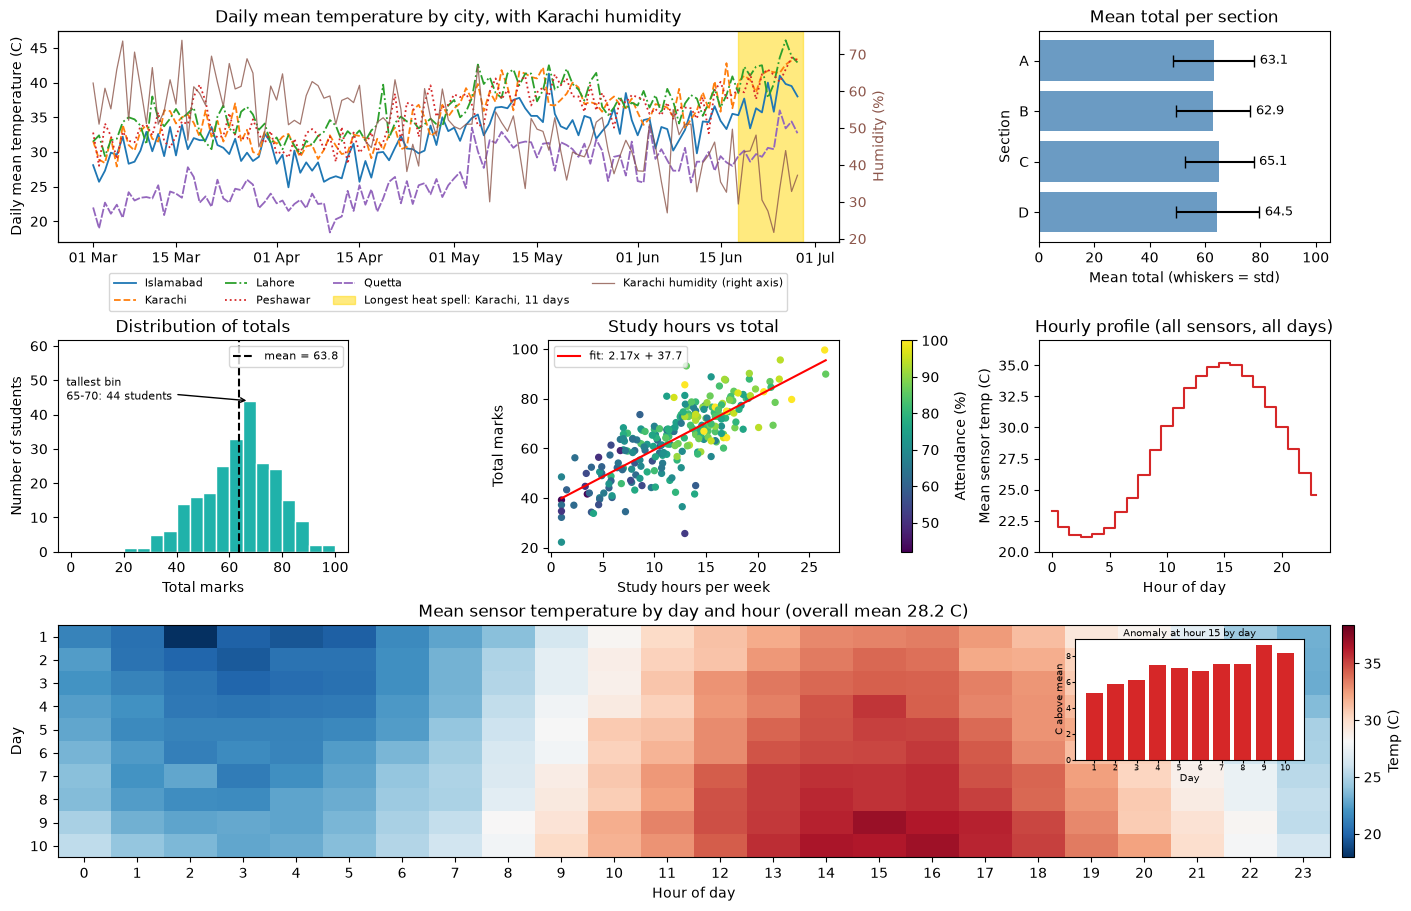

In [19]:
import os
import matplotlib.dates as mdates
os.makedirs('outputs', exist_ok=True)

# ---- data for the panels ----
daily_temp = weather.pivot_table(index='date', columns='city', values='temp_c')   # mean temp per city per day
karachi_hum = weather[weather['city'] == 'Karachi'].groupby('date')['humidity_pct'].mean()
day_hour = np.nanmean(calibrated, axis=2)            # 10 days x 24 hours, mean of the sensors
overall_mean = np.nanmean(day_hour)

fig = plt.figure(figsize=(14, 9), constrained_layout=True)
gs = GridSpec(3, 3, figure=fig, height_ratios=[1, 1, 1.1])
ax_temp = fig.add_subplot(gs[0, :2])
ax_bar = fig.add_subplot(gs[0, 2])
ax_hist = fig.add_subplot(gs[1, 0])
ax_sc = fig.add_subplot(gs[1, 1])
ax_step = fig.add_subplot(gs[1, 2])
ax_heat = fig.add_subplot(gs[2, :])

# ---- panel 1: city temperatures, heat spell, humidity on a twin axis ----
styles = ['-', '--', '-.', ':', (0, (5, 1))]
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
for city, ls, col in zip(daily_temp.columns, styles, colors):
    ax_temp.plot(daily_temp.index, daily_temp[city], linestyle=ls, color=col, linewidth=1.3, label=city)

longest = spells_df.loc[spells_df['length_days'].idxmax()]     # mark the longest heat spell
start = pd.Timestamp(longest['start_date'])
end = start + pd.Timedelta(days=int(longest['length_days']))
ax_temp.axvspan(start, end, color='gold', alpha=0.5,
                label=f"Longest heat spell: {longest['city']}, {int(longest['length_days'])} days")
ax_temp.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=[1, 15]))
ax_temp.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax_temp.set_ylabel('Daily mean temperature (C)')
ax_temp.set_title('Daily mean temperature by city, with Karachi humidity')

ax_hum = ax_temp.twinx()
ax_hum.plot(karachi_hum.index, karachi_hum.values, color='tab:brown', linewidth=0.9, alpha=0.8,
            label='Karachi humidity (right axis)')
ax_hum.set_ylabel('Humidity (%)', color='tab:brown')
ax_hum.tick_params(axis='y', labelcolor='tab:brown')

h1, l1 = ax_temp.get_legend_handles_labels()
h2, l2 = ax_hum.get_legend_handles_labels()
ax_temp.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8)

# ---- panel 2: mean total per section with std whiskers ----
y = np.arange(len(summary))
ax_bar.barh(y, summary['mean_total'], color='steelblue', alpha=0.8)
ax_bar.errorbar(summary['mean_total'], y, xerr=summary['std_total'], fmt='none', ecolor='black', capsize=4)
for yi, m, sd in zip(y, summary['mean_total'], summary['std_total']):
    ax_bar.text(m + sd + 2, yi, f'{m:.1f}', va='center', fontsize=9)
ax_bar.set_yticks(y)
ax_bar.set_yticklabels(summary.index)
ax_bar.invert_yaxis()
ax_bar.set_xlim(0, 105)
ax_bar.set_xlabel('Mean total (whiskers = std)')
ax_bar.set_ylabel('Section')
ax_bar.set_title('Mean total per section')

# ---- panel 3: histogram of totals ----
bins = np.arange(0, 105, 5)
counts, edges, _ = ax_hist.hist(students['total'], bins=bins, color='lightseagreen', edgecolor='white')
mean_total = students['total'].mean()
ax_hist.axvline(mean_total, linestyle='--', color='black', label=f'mean = {mean_total:.1f}')
tall = counts.argmax()
ax_hist.annotate(f'tallest bin\n{edges[tall]:.0f}-{edges[tall + 1]:.0f}: {counts[tall]:.0f} students',
                 xy=(edges[tall] + 2.5, counts[tall]), xycoords='data',          # arrow target in data coordinates
                 xytext=(0.03, 0.72), textcoords='axes fraction',                # text position in axes coordinates
                 fontsize=8, arrowprops=dict(arrowstyle='->'))
ax_hist.set_ylim(0, counts.max() * 1.4)        # head room for the annotation and legend
ax_hist.set_xlabel('Total marks')
ax_hist.set_ylabel('Number of students')
ax_hist.set_title('Distribution of totals')
ax_hist.legend(loc='upper right', fontsize=8)

# ---- panel 4: study hours vs total, coloured by attendance ----
sc = ax_sc.scatter(students['study_hours_week'], students['total'], c=students['attendance_pct'], cmap='viridis', s=18)
fig.colorbar(sc, ax=ax_sc, label='Attendance (%)')
xs = np.array([students['study_hours_week'].min(), students['study_hours_week'].max()])
ax_sc.plot(xs, slope * xs + intercept, color='red', label=f'fit: {slope:.2f}x + {intercept:.1f}')
ax_sc.set_xlabel('Study hours per week')
ax_sc.set_ylabel('Total marks')
ax_sc.set_title('Study hours vs total')
ax_sc.legend(loc='upper left', fontsize=8)

# ---- panel 5: hourly sensor-average profile as a step plot ----
ax_step.step(np.arange(24), hour_profile, where='mid', color='tab:red')
# y-limits: the profile range plus 1 degree each side, so the whole curve is visible.
# The axis does not start at 0 because 0 is far from the data (it would squash the curve flat).
ax_step.set_ylim(np.floor(hour_profile.min()) - 1, np.ceil(hour_profile.max()) + 1)
ax_step.set_xlabel('Hour of day')
ax_step.set_ylabel('Mean sensor temp (C)')
ax_step.set_title('Hourly profile (all sensors, all days)')

# ---- panel 6: day x hour heatmap with inset ----
half = np.nanmax(np.abs(day_hour - overall_mean))
im = ax_heat.imshow(day_hour, aspect='auto', cmap='RdBu_r',
                    vmin=overall_mean - half, vmax=overall_mean + half)   # centred on the overall mean
ax_heat.set_xticks(np.arange(24))
ax_heat.set_yticks(np.arange(10))
ax_heat.set_yticklabels(meta['days'])                                      # real day numbers
ax_heat.set_xlabel('Hour of day')
ax_heat.set_ylabel('Day')
ax_heat.set_title(f'Mean sensor temperature by day and hour (overall mean {overall_mean:.1f} C)')
fig.colorbar(im, ax=ax_heat, label='Temp (C)', fraction=0.025, pad=0.01)

anomaly = day_hour - overall_mean
d_max, h_max = np.unravel_index(np.nanargmax(anomaly), anomaly.shape)      # cell with the biggest anomaly
inset = ax_heat.inset_axes([0.80, 0.42, 0.18, 0.52])       # inset sits over the mild evening hours (hours 20-23)
inset.bar(meta['days'], anomaly[:, h_max], color='tab:red')
inset.set_title(f'Anomaly at hour {h_max} by day', fontsize=7, pad=2)
inset.set_xlabel('Day', fontsize=7, labelpad=1)
inset.set_ylabel('C above mean', fontsize=7, labelpad=1)
inset.set_xticks(meta['days'])
inset.tick_params(labelsize=6, length=2, pad=1)

fig.savefig('outputs/dashboard.png', dpi=200)
fig.savefig('outputs/dashboard.pdf')
print('hour with maximum anomaly:', h_max, '| on day', meta['days'][d_max], '| anomaly', anomaly[d_max, h_max].round(2))
print('saved outputs/dashboard.png and outputs/dashboard.pdf')


**ANSWER 6 (4 sentences):** Using specific numbers from your dashboard, tell a plant manager what the single most important finding is, and name one panel whose design could mislead a reader and why.

The most important finding for the plant manager is that the site gets hottest around hour 15 every day (hourly mean 35.2 C against 21.2 C at hour 3), and the heatmap shows the hottest cell at day 9, hour 15, which is 8.9 C above the overall mean of 28.2 C, so cooling and shift planning should focus on about 12:00 to 17:00 and on the later days. The weather panel adds that Karachi had an 11-day heat spell above 38 C from 18 June, the longest of all cities (the data ends on 28 June, so it may be even longer). The step plot in panel 5 could mislead a reader because its y-axis starts at 20 C instead of 0, which makes the 14.0 C day-night swing look much bigger relative to the temperature than it really is. Panel 4 also needs care, because the fitted line (slope 2.17 marks per study hour) shows association between study hours and marks, not that studying more causes the marks.

## Question 7: Surfaces and animation (10 marks)
Let f(x, y) = sin(r) / r with r = sqrt(x^2 + y^2) on x, y in [-10, 10].

**7a (4 marks)** Build the grid with `meshgrid` of 201 points per axis. Handle r = 0 correctly (the limit is 1; a plain division gives NaN, show you saw it and fixed it with `np.where`). Draw side by side: `pcolormesh` with a diverging colormap and symmetric `vmin`/`vmax`, and `contourf` with `contour` lines labelled using `clabel`. Add colorbars. Count (with Boolean sums) how many grid points have f below -0.1 and say what visual feature that corresponds to.

NaN with plain division: 1 at grid position [100 100]
NaN after the fix: 0 | value at the centre: 1.0
grid points with f < -0.1: 6280 out of 40401
their distance from the centre r: from 3.5 to 5.68
lowest value of f: -0.217


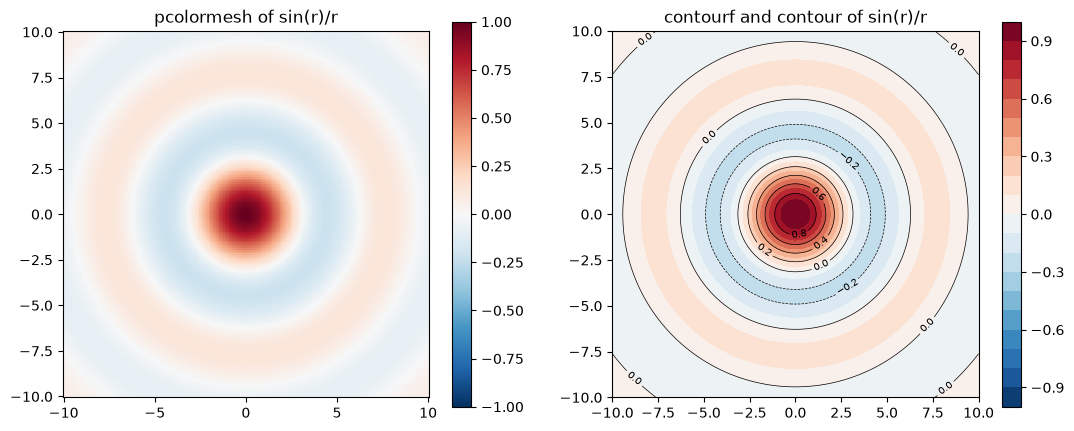

In [20]:
x = np.linspace(-10, 10, 201)
y = np.linspace(-10, 10, 201)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)

# plain division gives 0/0 = NaN at the centre
with np.errstate(invalid='ignore'):
    Z_plain = np.sin(R) / R
print('NaN with plain division:', np.isnan(Z_plain).sum(), 'at grid position', np.argwhere(np.isnan(Z_plain))[0])

# fix with np.where: the limit of sin(r)/r at r = 0 is 1 (R_safe only avoids dividing by 0)
R_safe = np.where(R == 0, 1, R)
Z = np.where(R == 0, 1.0, np.sin(R_safe) / R_safe)
print('NaN after the fix:', np.isnan(Z).sum(), '| value at the centre:', Z[100, 100])

lim = np.abs(Z).max()                      # symmetric colour limits
levels = np.linspace(-lim, lim, 21)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 5))
pm = ax_a.pcolormesh(X, Y, Z, cmap='RdBu_r', vmin=-lim, vmax=lim, shading='auto')
fig.colorbar(pm, ax=ax_a)
ax_a.set_title('pcolormesh of sin(r)/r')
ax_a.set_aspect('equal')

cf = ax_b.contourf(X, Y, Z, levels=levels, cmap='RdBu_r')
cs = ax_b.contour(X, Y, Z, levels=levels[::2], colors='k', linewidths=0.5)
ax_b.clabel(cs, fontsize=7)
fig.colorbar(cf, ax=ax_b)
ax_b.set_title('contourf and contour of sin(r)/r')
ax_b.set_aspect('equal')

low = Z < -0.1
print('grid points with f < -0.1:', low.sum(), 'out of', Z.size)
print('their distance from the centre r: from', R[low].min().round(2), 'to', R[low].max().round(2))
print('lowest value of f:', Z.min().round(3))


**7b (3 marks)** Make a 3D surface with `plot_surface` using `rstride=5, cstride=5`, then a `plot_wireframe` of the same data, and add a contour projection onto the floor (`zdir="z"`, with offset below the minimum). Use `view_init(elev=35, azim=-60)`. Explain what changes if rstride and cstride are set to 1 and why.

floor offset: -0.517
stride 5: faces about 1600 | wireframe lines 41 + 41 = 82
stride 1: faces about 40000 | wireframe lines 201 + 201 = 402
With stride 1 every grid point is used: 25 times more faces, the plot is slower to draw, and the
black wireframe lines are so close together that they cover the surface colours and look like a dark mass.
The shape is smooth, so stride 5 already shows it and nothing new is gained.


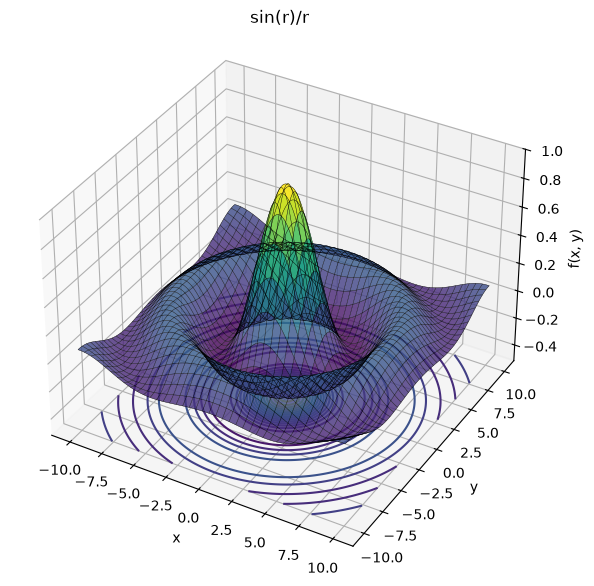

In [21]:
fig = plt.figure(figsize=(10, 7))
ax3 = fig.add_subplot(projection='3d')
ax3.plot_surface(X, Y, Z, rstride=5, cstride=5, cmap='viridis', alpha=0.8)
ax3.plot_wireframe(X, Y, Z, rstride=5, cstride=5, color='k', linewidth=0.3)
floor = Z.min() - 0.3                                   # floor below the minimum of Z
ax3.contour(X, Y, Z, zdir='z', offset=floor, cmap='viridis', levels=15)
ax3.set_zlim(floor, 1)
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_zlabel('f(x, y)')
ax3.view_init(elev=35, azim=-60)
ax3.set_title('sin(r)/r')

n5 = len(range(0, 201, 5))
print('floor offset:', round(floor, 3))
print('stride 5: faces about', (n5 - 1) ** 2, '| wireframe lines', n5, '+', n5, '=', 2 * n5)
print('stride 1: faces about', 200 * 200, '| wireframe lines 201 + 201 =', 402)
print('With stride 1 every grid point is used: 25 times more faces, the plot is slower to draw, and the')
print('black wireframe lines are so close together that they cover the surface colours and look like a dark mass.')
print('The shape is smooth, so stride 5 already shows it and nothing new is gained.')


**7c (3 marks)** Animate the travelling wave sin(r - 0.3 t)/r along the line y = 0 using `FuncAnimation` with 60 frames, `interval=50` and `blit=True`. Your update function must return the artist(s). Save as `wave.gif` with `PillowWriter`. Do not use `plt.show()` blocking calls. Say in a comment why blit needs the update function to return a tuple.

In [22]:
import os
os.makedirs('outputs', exist_ok=True)

# even number of points, so x = 0 is not on the grid (the formula divides by r)
x_line = np.linspace(-10, 10, 400)
r_line = np.abs(x_line)                         # on the line y = 0, r = |x|

fig, ax = plt.subplots(figsize=(8, 4))
line, = ax.plot(x_line, np.sin(r_line) / r_line)
ax.set_xlim(-10, 10)
ax.set_ylim(-1.2, 1.2)                          # fixed limits; the spike next to x = 0 is cut off
ax.set_xlabel('x')
ax.set_ylabel('f')
ax.set_title('Travelling wave sin(r - 0.3 t)/r along y = 0')

def init():
    return (line,)

def update(frame):
    t = frame
    line.set_ydata(np.sin(r_line - 0.3 * t) / r_line)
    # blit redraws only the returned artists; matplotlib loops over what we return,
    # so it must be a tuple (or list) of artists, not one bare artist
    return (line,)

ani = FuncAnimation(fig, update, frames=60, init_func=init, interval=50, blit=True)
ani.save('outputs/wave.gif', writer=PillowWriter(fps=20))   # interval 50 ms = 20 frames per second
plt.close(fig)
print('saved outputs/wave.gif')


saved outputs/wave.gif


## Final checklist
- Restart and Run All works
- All ANSWER cells filled
- `dashboard.png`, `dashboard.pdf` and `wave.gif` are created by your notebook
- Code pushed to GitHub as described in the PDF